# Predicting Limit Order Books, and Whether the Prediction Pays

**Machine Learning course project, final notebook.** Author: Aarav Singhal. October 2026.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aaravsin-1/ML_Project_2026/blob/master/submission/Final_Project_Notebook.ipynb)

This notebook walks through every experiment in the project, with the question each one asks, how it works, its results and what they mean. The written argument is in [PROJECT_REPORT.md](PROJECT_REPORT.md), and the full per-experiment write-up is in the repository's [README](../README.md).

**The question.** Can machine learning predict the next few seconds of price movement from a limit order book, and can a trading system turn that prediction into profit? Profit depends on three things at once:
- how **accurate** the prediction is;
- how **fast** the system acts on it (latency);
- what it **costs** to trade.

**How to run this notebook.** Choose **Runtime → Run all**. It takes a few minutes and needs no GPU or credentials:
- The setup cell clones the repository (on Colab).
- Section 3 runs a small **live demo** that builds features, trains models, validates them and simulates trading on a synthetic order book.
- Every other section **loads the saved results** of the full experiments from `artifacts/`. Those experiments take hours and some need a GPU.
- To recompute an experiment, switch it on in the `RERUN` settings in section 1. That needs Kaggle credentials for the data and, for the deep models, a GPU. [notebooks/colab_run_all.ipynb](../notebooks/colab_run_all.ipynb) reruns everything with checkpointing.

**Contents**
1. Setup
2. The question, the data and the method
3. Live demo: the pipeline end to end on a synthetic book
4. Synthetic experiments A–D
5. Real data: Coinbase BTC-USD (A–D)
6. From prediction to profit on BTC (E, edge decomposition, G)
7. More signal: Ethereum's book (F)
8. Market making (H) and Nasdaq stocks by tick size (I)
9. Is the ranking significant, and what do the models use? (J)
10. The micro-price as predictor and target (K)
11. FI-2010: comparison with the published DeepLOB
12. Optiver Kaggle data: leakage and the closing auction
13. Latency: the C++ inference benchmarks
14. Discussion: balancing accuracy, latency and cost
15. Limitations and conclusion

## 1. Setup

Clones the repository on Colab (locally, it finds the repository root), installs the few packages Colab lacks, and defines small helpers for showing results.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO = "aaravsin-1/ML_Project_2026"

if IN_COLAB:
    root = Path("/content/ML_Project_2026")
    if not root.exists():
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")      # only needed if the repository is private
        except Exception:
            token = None
        url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"
        subprocess.run(["git", "clone", "--depth", "1", url, str(root)], check=True)
    os.chdir(root)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm>=4.0", "kaggle"], check=False)
else:
    root = Path.cwd()
    while not (root / "src" / "experiments").exists() and root != root.parent:
        root = root.parent
    os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
print("Repository:", root)
print("Code at commit:", subprocess.run(["git", "log", "-1", "--format=%h %ci"], capture_output=True, text=True).stdout.strip())

Repository: /home/varaa/Documents/a_Coding/ML_Project_2026
Code at commit: 64126d0 2026-10-31 14:19:54 +0530


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
ART = root / "artifacts"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"


def load(path):
    return pd.read_csv(ART / path)


def show(df, digits=3):
    """Displays a table with its first column as the row label."""
    display(df.set_index(df.columns[0]).round(digits))


def figure(path, width=900):
    display(Image(filename=str(ART / path), width=width))

**Rerunning experiments (optional).** Every switch is off, so the notebook shows the saved results. Switching one on reruns that experiment before its results are shown.
- **Checkpoints:** experiments resume from saved checkpoints where they exist, so finished parts are reused.
- **Data:** BTC, FI-2010 and Optiver are downloaded from Kaggle. Add `KAGGLE_USERNAME` and `KAGGLE_KEY` as Colab secrets (🔑 panel) and accept the Optiver competitions' rules on kaggle.com.
- **LOBSTER:** cannot be downloaded automatically (academic licence). Put the 10-level sample files in `data/raw/lobster/`.
- **Run times** are noted per switch.

In [3]:
RERUN = {
    "validation": False,          # leakage / robustness report, synthetic       CPU, ~5 min
    "synthetic": False,           # Experiments A-D on 5 synthetic sessions      GPU recommended, ~10 min
    "btc": False,                 # Experiments A-D on 4 BTC segments            GPU, ~3 h
    "btc_tradability": False,     # Experiment E                                 CPU, ~20 min
    "btc_edge": False,            # edge decomposition (needs Experiment G)      CPU, ~2 min
    "btc_eth": False,             # Experiment F                                 CPU, ~20 min
    "btc_regimes": False,         # Experiment G                                 CPU, ~10 min
    "btc_market_making": False,   # Experiment H                                 CPU, ~5 min
    "lobster": False,             # Experiment I (needs LOBSTER files)           CPU, ~15 min
    "attribution": False,         # Experiment J; DeepLOB part needs a GPU       GPU, ~1.5 h
    "microprice": False,          # Experiment K (BTC; LOBSTER if present)       CPU, ~1 h
    "fi2010": False,              # FI-2010 Setup 2, 3 seeds                     GPU, ~2 h
    "fi2010_diagnose": False,     # FI-2010 LightGBM diagnostic                  CPU, ~10 min
    "optiver_rvp": False,         # Optiver Realized Volatility                  CPU, ~1 h
    "optiver_close": False,       # Optiver Trading at the Close                 CPU, ~1 h
    "cpp_trained": False,         # trained LightGBM compiled to C++             CPU, ~5 min
}

PY = f"{sys.executable} -u -W ignore"
STEPS = {
    "validation": (f"{PY} scripts/verify_robustness_and_leakage.py --seed 42 --events 60000", []),
    "synthetic": (f"{PY} scripts/run_all_experiments.py --source synthetic --seeds 0 1 2 3 4 --epochs 10", []),
    "btc": (f"{PY} scripts/run_all_experiments.py --source btc --segments 4 --epochs 8", ["btc"]),
    "btc_tradability": (f"{PY} -m src.experiments.exp_e_tradability", ["btc"]),
    "btc_edge": (f"{PY} scripts/decompose_btc_edge.py", ["btc"]),
    "btc_eth": (f"{PY} -m src.experiments.exp_f_cross_asset", ["btc", "eth"]),
    "btc_regimes": (f"{PY} -m src.experiments.exp_g_regimes", ["btc"]),
    "btc_market_making": (f"{PY} -m src.experiments.exp_h_market_making", ["btc"]),
    "lobster": (f"{PY} -m src.experiments.exp_i_lobster", []),
    "attribution": (f"{PY} -m src.experiments.exp_j_attribution" + (" --deeplob" if IN_COLAB else ""), ["btc"]),
    "microprice": (f"{PY} -m src.experiments.exp_k_microprice && {PY} scripts/check_microprice_results.py", ["btc"]),
    "fi2010": (f"{PY} -m src.experiments.fi2010_benchmark --epochs 15 --seeds 0 1 2", ["fi2010"]),
    "fi2010_diagnose": (f"{PY} scripts/diagnose_fi2010_lightgbm.py", ["fi2010"]),
    "optiver_rvp": (f"{PY} -m src.experiments.optiver_rvp", ["optiver_rvp"]),
    "optiver_close": (f"{PY} -m src.experiments.optiver_close", ["optiver_close"]),
    "cpp_trained": (f"{PY} scripts/benchmark_trained_model.py", ["btc"]),
}


def rerun(name):
    """Reruns one experiment if it is switched on in RERUN; otherwise says the saved results are shown."""
    if not RERUN.get(name):
        print(f"Showing saved results. (Set RERUN['{name}'] = True in section 1 to recompute.)")
        return
    cmd, data = STEPS[name]
    if data and IN_COLAB:
        from google.colab import userdata
        for key in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
            try:
                os.environ[key] = userdata.get(key)
            except Exception:
                pass
    for d in data:
        if subprocess.run([sys.executable, "scripts/fetch_datasets.py", d]).returncode != 0:
            print(f"[!] Could not download {d}; showing saved results instead.")
            return
    print(f"[>] {cmd}\n", flush=True)
    proc = subprocess.Popen(cmd, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="", flush=True)
    print(f"\n[{'+' if proc.wait() == 0 else '!'}] {name} finished with exit code {proc.returncode}")

## 2. The question, the data and the method

### 2.1 Why accuracy alone is not enough

For one round trip (enter, hold for horizon $h$, exit), the net edge splits into four parts:

$$\text{net edge} = \underbrace{E[s\,\Delta m_{t\to t+h}]}_{\text{accuracy}} - \underbrace{\big(E[s\,\Delta m_{t\to t+h}] - E[s\,\Delta m_{t+L\to t+L+h}]\big)}_{\text{latency } L} - \underbrace{c_{\text{cross}}}_{\text{spread, depth}} - \underbrace{2f}_{\text{fees}}$$

Here $s=\pm1$ is the predicted direction and $\Delta m$ the change in the mid price (halfway between the best bid and best ask).
- The **model** controls the first term.
- The **system's speed** controls the second.
- The **market and exchange** control the last two.

If moves are roughly symmetric with average size $m$ and the model is right with probability $p$, the first term is about $(2p-1)m$. Breaking even after a total round-trip cost $C$ then needs a hit rate of

$$p^* = \tfrac12 + \frac{C}{2m}.$$

When $C > m$, $p^* > 1$ and no model can win. Section 14 comes back to this.

### 2.2 Data

| Dataset | What it is | Role |
|:---|:---|:---|
| Synthetic | Simulated large-tick book with a planted "informed trader" signal, 5 × 60,000 events | Controlled tests and the latency sweep. Says nothing about real markets |
| Coinbase BTC-USD | 15-level book, 1 s snapshots, real trade tape, ~12 days (Apr 2021), 4 segments | Main real-data testbed |
| LOBSTER | Every Nasdaq order event for INTC, MSFT, AAPL, AMZN and GOOG, 21 June 2012, resampled to 100 ms | Large-tick vs small-tick stocks, 100 ms to 30 s horizons |
| FI-2010 | Academic benchmark: 5 Finnish stocks, 10 days | Comparison with the published DeepLOB |
| Optiver Realized Volatility | Kaggle 2021 | Leakage case study |
| Optiver Trading at the Close | Kaggle 2023 | Regression on the closing auction |

**Tick size** shapes everything:
- **Large-tick** stocks (INTC, MSFT): the 1-cent tick is 3.3–3.7 bp of the price, the spread is usually one tick, and the queues are deep.
- **Small-tick** stocks (AAPL, AMZN, GOOG): 0.17–0.45 bp.
- **BTC**: the tick is $0.01 on about $60,000, which is 0.0017 bp.

(1 bp = 0.01%.)

### 2.3 Method

**Task.** Predict whether the smoothed mid price $k$ steps ahead is UP, FLAT or DOWN. The UP/DOWN threshold is fitted on training rows only. On BTC it is set so that a third of training rows are FLAT, which puts random guessing at macro-F1 ≈ 0.333.

**Metric.** Macro-F1 is the average F1 over the three classes, so a model cannot score well by always predicting the majority class.

**Features.** All features are causal: row $t$ uses only snapshots at or before $t$.
- Queue imbalance at levels 1, 3, 5 and 10.
- Spread in ticks.
- Order flow imbalance (OFI, Cont et al. 2014), plus multi-level OFI compressed by a train-only PCA.
- VPIN (Easley et al. 2012), a measure of how one-sided recent trading was.
- Micro-price deviation.
- Book slopes.
- Lags of the level-1 signals.

**Models.**

| Tier | Model |
|:---:|:---|
| 0 | Naive momentum (repeat the last realised move), naive flat |
| 1 | Logistic regression |
| 2 | Random Forest |
| 3 | LightGBM (gradient-boosted trees) |
| 4 | LSTM on windows of 100 raw book snapshots |
| 5 | DeepLOB (CNN + Inception + LSTM), TLOB (transformer) |

**Validation against leakage.**
- **Splits:** chronological 70/15/15. The last $k$ rows before each boundary are purged, because their labels look into the next split.
- **Train-only fitting:** every normaliser, PCA and threshold is fitted on the training period.
- **Same test rows** for every model.
- **Significance:** moving-block bootstrap confidence intervals and McNemar's test.
- **Negative controls:** shuffled-target models must score about zero.
- **Tests:** 40 automated tests.

**Execution simulator.**
- **Taker orders** cross the spread and walk the book level by level, and pay fees.
- **Latency** is applied in wall-clock time.
- **Passive orders** use three fill rules that bracket the truth: pessimistic (only when the price trades through), queue, and optimistic (front of the queue).

## 3. Live demo: the pipeline end to end on a synthetic book

This section really runs. It generates one synthetic session, builds the features, trains the tabular models, validates them and simulates trading. The full synthetic experiments in section 4 repeat this over 5 sessions and add the deep models. It takes about 2–4 minutes on a CPU.

### 3.1 Generate a market and build features
60,000 events of a large-tick book (one-tick spread, 10 levels, about 10 ms between events). The generator plants a hidden informed-trader state that skews order flow for 15–60 events at a time.

In [4]:
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef
from src.experiments.common import generate_session, prepare_data
from src.models.baselines import NaiveMomentumBaseline, NaiveFlatBaseline, LogisticRegressionBaseline
from src.models.tabular_trees import RandomForestLOB, LightGBMLOB

SEED, k = 42, 20
np.random.seed(SEED)
session = generate_session(SEED, n_events=60000)
y_all = session.labels_dict[k]
data = prepare_data(session)                 # PCA and normaliser fitted on the training period only
idx = data.splits(k)                         # chronological 70/15/15 with a purge gap of k rows
X = data.tab_feat
X_tr, y_tr = X[idx["train"]], y_all[idx["train"]]
X_va, y_va = X[idx["val"]], y_all[idx["val"]]
X_te, y_te = X[idx["test"]], y_all[idx["test"]]

print(f"{len(session.lob_40):,} snapshots over {session.timestamps_ms[-1] / 1000:.0f} s of simulated trading")
print(f"{len(data.feat_names)} features, e.g. {', '.join(data.feat_names[:6])}, ...")
print(f"Train {len(X_tr):,} | validation {len(X_va):,} | test {len(X_te):,} rows")
print("Test label shares (FLAT / UP / DOWN):", np.round(np.bincount(y_te, minlength=3) / len(y_te), 3))

60,000 snapshots over 602 s of simulated trading
27 features, e.g. imbalance_l1, imbalance_l3, imbalance_l5, imbalance_l10, spread_ticks, micro_deviation, ...
Train 41,881 | validation 8,980 | test 8,980 rows
Test label shares (FLAT / UP / DOWN): [0.666 0.174 0.159]


### 3.2 Train the model ladder
All learned models use balanced class weights. The momentum baseline repeats the last *realised* move (the label at $t-k$), the latest information actually available when the decision is made.

In [5]:
rows = []
def record(name, pred):
    rows.append({"Model": name, "Accuracy": accuracy_score(y_te, pred),
                 "Macro-F1": f1_score(y_te, pred, average="macro"), "MCC": matthews_corrcoef(y_te, pred)})

record("Naive flat", NaiveFlatBaseline().predict(X_te))
record("Naive momentum (lag k)", NaiveMomentumBaseline(k).predict(y_all, idx["test"]))
lr = LogisticRegressionBaseline(C=1.0); lr.fit(X_tr, y_tr); record("Logistic regression", lr.predict(X_te))
rf = RandomForestLOB(n_estimators=100, max_depth=10, random_state=SEED); rf.fit(X_tr, y_tr); record("Random Forest", rf.predict(X_te))
lgb = LightGBMLOB(num_leaves=63, max_depth=8, learning_rate=0.05, n_estimators=200, random_state=SEED)
lgb.fit(X_tr, y_tr, X_va, y_va, early_stopping_rounds=15)
pred_lgb = lgb.predict(X_te)
record("LightGBM", pred_lgb)
show(pd.DataFrame(rows))

,Accuracy,Macro-F1,MCC
Model,,,
Naive flat,0.666,0.267,0.000
Naive momentum (lag k),0.619,0.519,0.238
Logistic regression,0.593,0.580,0.395
Random Forest,0.627,0.606,0.414
LightGBM,0.639,0.615,0.425


Accuracy is below the naive-flat rate for every learned model. That's expected: balanced class weights trade majority-class accuracy for recall on UP and DOWN. Macro-F1 and MCC are the fair comparison, and on both the learned models clearly beat the baselines.

### 3.3 Validate: purged cross-validation and a shuffled-target control
- **Purged CV with embargo** checks that the skill is stable across time.
- **The permutation check** trains on shuffled targets and must find no skill. It catches label/row misalignment, though it cannot by itself prove that features don't look ahead. The causality test in the test suite covers that.

In [6]:
from src.utils.validation_checks import OverfittingDiagnostics

cv = OverfittingDiagnostics.run_purged_cv_evaluation(LightGBMLOB, X, y_all, n_splits=5, horizon_k=k, embargo_pct=0.01)
print(f"Purged CV macro-F1: {cv['test_macro_f1'].mean():.3f} ± {cv['test_macro_f1'].std():.3f} over {len(cv)} folds")
perm = OverfittingDiagnostics.run_permutation_reality_check(LightGBMLOB, X_tr, y_tr, X_te, y_te, n_permutations=3)
print(f"Shuffled-target macro-F1: {perm['permuted_macro_f1']:.3f} (chance ≈ 0.33), MCC {perm['permuted_mcc']:+.3f}",
      "-> FAIL" if perm["leakage_detected"] else "-> PASS: no skill without real labels")

Purged CV macro-F1: 0.588 ± 0.006 over 4 folds


Shuffled-target macro-F1: 0.279 (chance ≈ 0.33), MCC -0.038 -> PASS: no skill without real labels


### 3.4 Simulate trading on LightGBM's signals
Three regimes, all at 1 ms latency:
- **Fantasy:** fills at the mid with no costs. This is what many papers report, and it's an upper bound.
- **Aggressive taker:** crosses the spread, walks the book and pays a 1.5 bp fee.
- **Passive maker:** joins the best price, counts as filled only when the market trades through it, and stands down when VPIN is high.

In [7]:
from src.execution.simulator import ExecutionSimulator
from src.execution.strategies import MicrostructureStrategyRunner
from src.execution.metrics import PerformanceMetrics

t_idx = idx["test"]
lob_te, ts_te = session.lob_40[t_idx], session.timestamps_ms[t_idx]
vpin = X[:, data.feat_names.index("vpin")]
vpin_cut = float(np.quantile(vpin[:data.train_end], 0.90))
sim = ExecutionSimulator(initial_cash=1_000_000.0, maker_fee_bps=-0.5, taker_fee_bps=1.5, lot_size=100.0,
                         latency_ms=1.0, timestamps_ms=ts_te)
runner = MicrostructureStrategyRunner(sim)
runs = {"Fantasy (mid, no costs)": runner.run_academic_midprice(pred_lgb, (lob_te[:, 0] + lob_te[:, 2]) / 2),
        "Aggressive taker": runner.run_realistic_aggressive(pred_lgb, lob_te),
        "Passive maker (VPIN gate)": runner.run_dynamic_passive_vpin(pred_lgb, lob_te, vpin[t_idx], vpin_cut)}
out = []
for name, res in runs.items():
    perf = PerformanceMetrics.calculate_metrics(res["equity"], 1_000_000.0, timestamps_ms=ts_te, bar_ms=100.0)
    out.append({"Regime": name, "Net P&L ($)": perf["net_pnl"], "Trades": res["num_trades"],
                "Fees ($)": res.get("total_fees", 0.0), "Slippage ($)": res.get("total_slippage", 0.0)})
print(f"Test window: {(ts_te[-1] - ts_te[0]) / 1000:.0f} s of simulated trading")
show(pd.DataFrame(out), 1)

Test window: 90 s of simulated trading


,Net P&L ($),Trades,Fees ($),Slippage ($)
Regime,,,,
"Fantasy (mid, no costs)",1987.0,831,0.0,0.0
Aggressive taker,253.3,831,1214.3,519.3
Passive maker (VPIN gate),23.9,9,-4.4,0.0


The same signals that earn money at the mid lose most of it, or all of it, once the spread and fees are paid. Passive orders barely fill under the honest trade-through rule. That gap between "predictable" and "profitable" is the subject of the rest of the notebook.

## 4. Synthetic experiments A–D (5 sessions)

The same pipeline over 5 independently generated sessions, now including the deep models. Because the generator plants the signal, these results test the *method*, not markets.

### 4.0 Leakage and robustness report
A single session (seed 42), checked against stated criteria. Each PASS or FAIL is computed from the value, never written in by hand.

In [8]:
rerun("validation")
show(load("overfitting_verification_report.csv"))

Showing saved results. (Set RERUN['validation'] = True in section 1 to recompute.)


,value,criterion,status
check,,,
Generalization Gap (F1 Train - Test),0.121,< 0.25,PASS
Test Matthews Correlation Coef (MCC),0.425,> 0,PASS
Test Cohen's Kappa,0.400,> 0,PASS
Test Macro-F1 lift over naive momentum (lag k),0.096,> 0,PASS
Purged CV Mean Macro-F1,0.588,fold std < 0.05,PASS
Purged CV Min MCC,0.386,every fold > 0,PASS
Permutation Check Macro-F1,0.288,<= 0.45,PASS
Permutation Check MCC,-0.026,|MCC| <= 0.10,PASS
Cross-Regime Small-Tick Transfer Macro-F1,0.509,MCC > 0,PASS


### 4.1 Experiment A: which model predicts best? (k = 20 events)

Showing saved results. (Set RERUN['synthetic'] = True in section 1 to recompute.)


,accuracy,macro_f1,macro_f1_std,cross_entropy
model,,,,
Naïve Momentum,0.645,0.519,0.013,0.961
Naïve Flat,0.698,0.274,0.003,4.812
Logistic Regression,0.587,0.564,0.007,0.812
Random Forest,0.609,0.578,0.008,0.757
LightGBM,0.620,0.584,0.012,0.743
LSTM,0.552,0.521,0.023,0.859
DeepLOB,0.597,0.559,0.010,0.823
TLOB,0.535,0.492,0.018,0.965


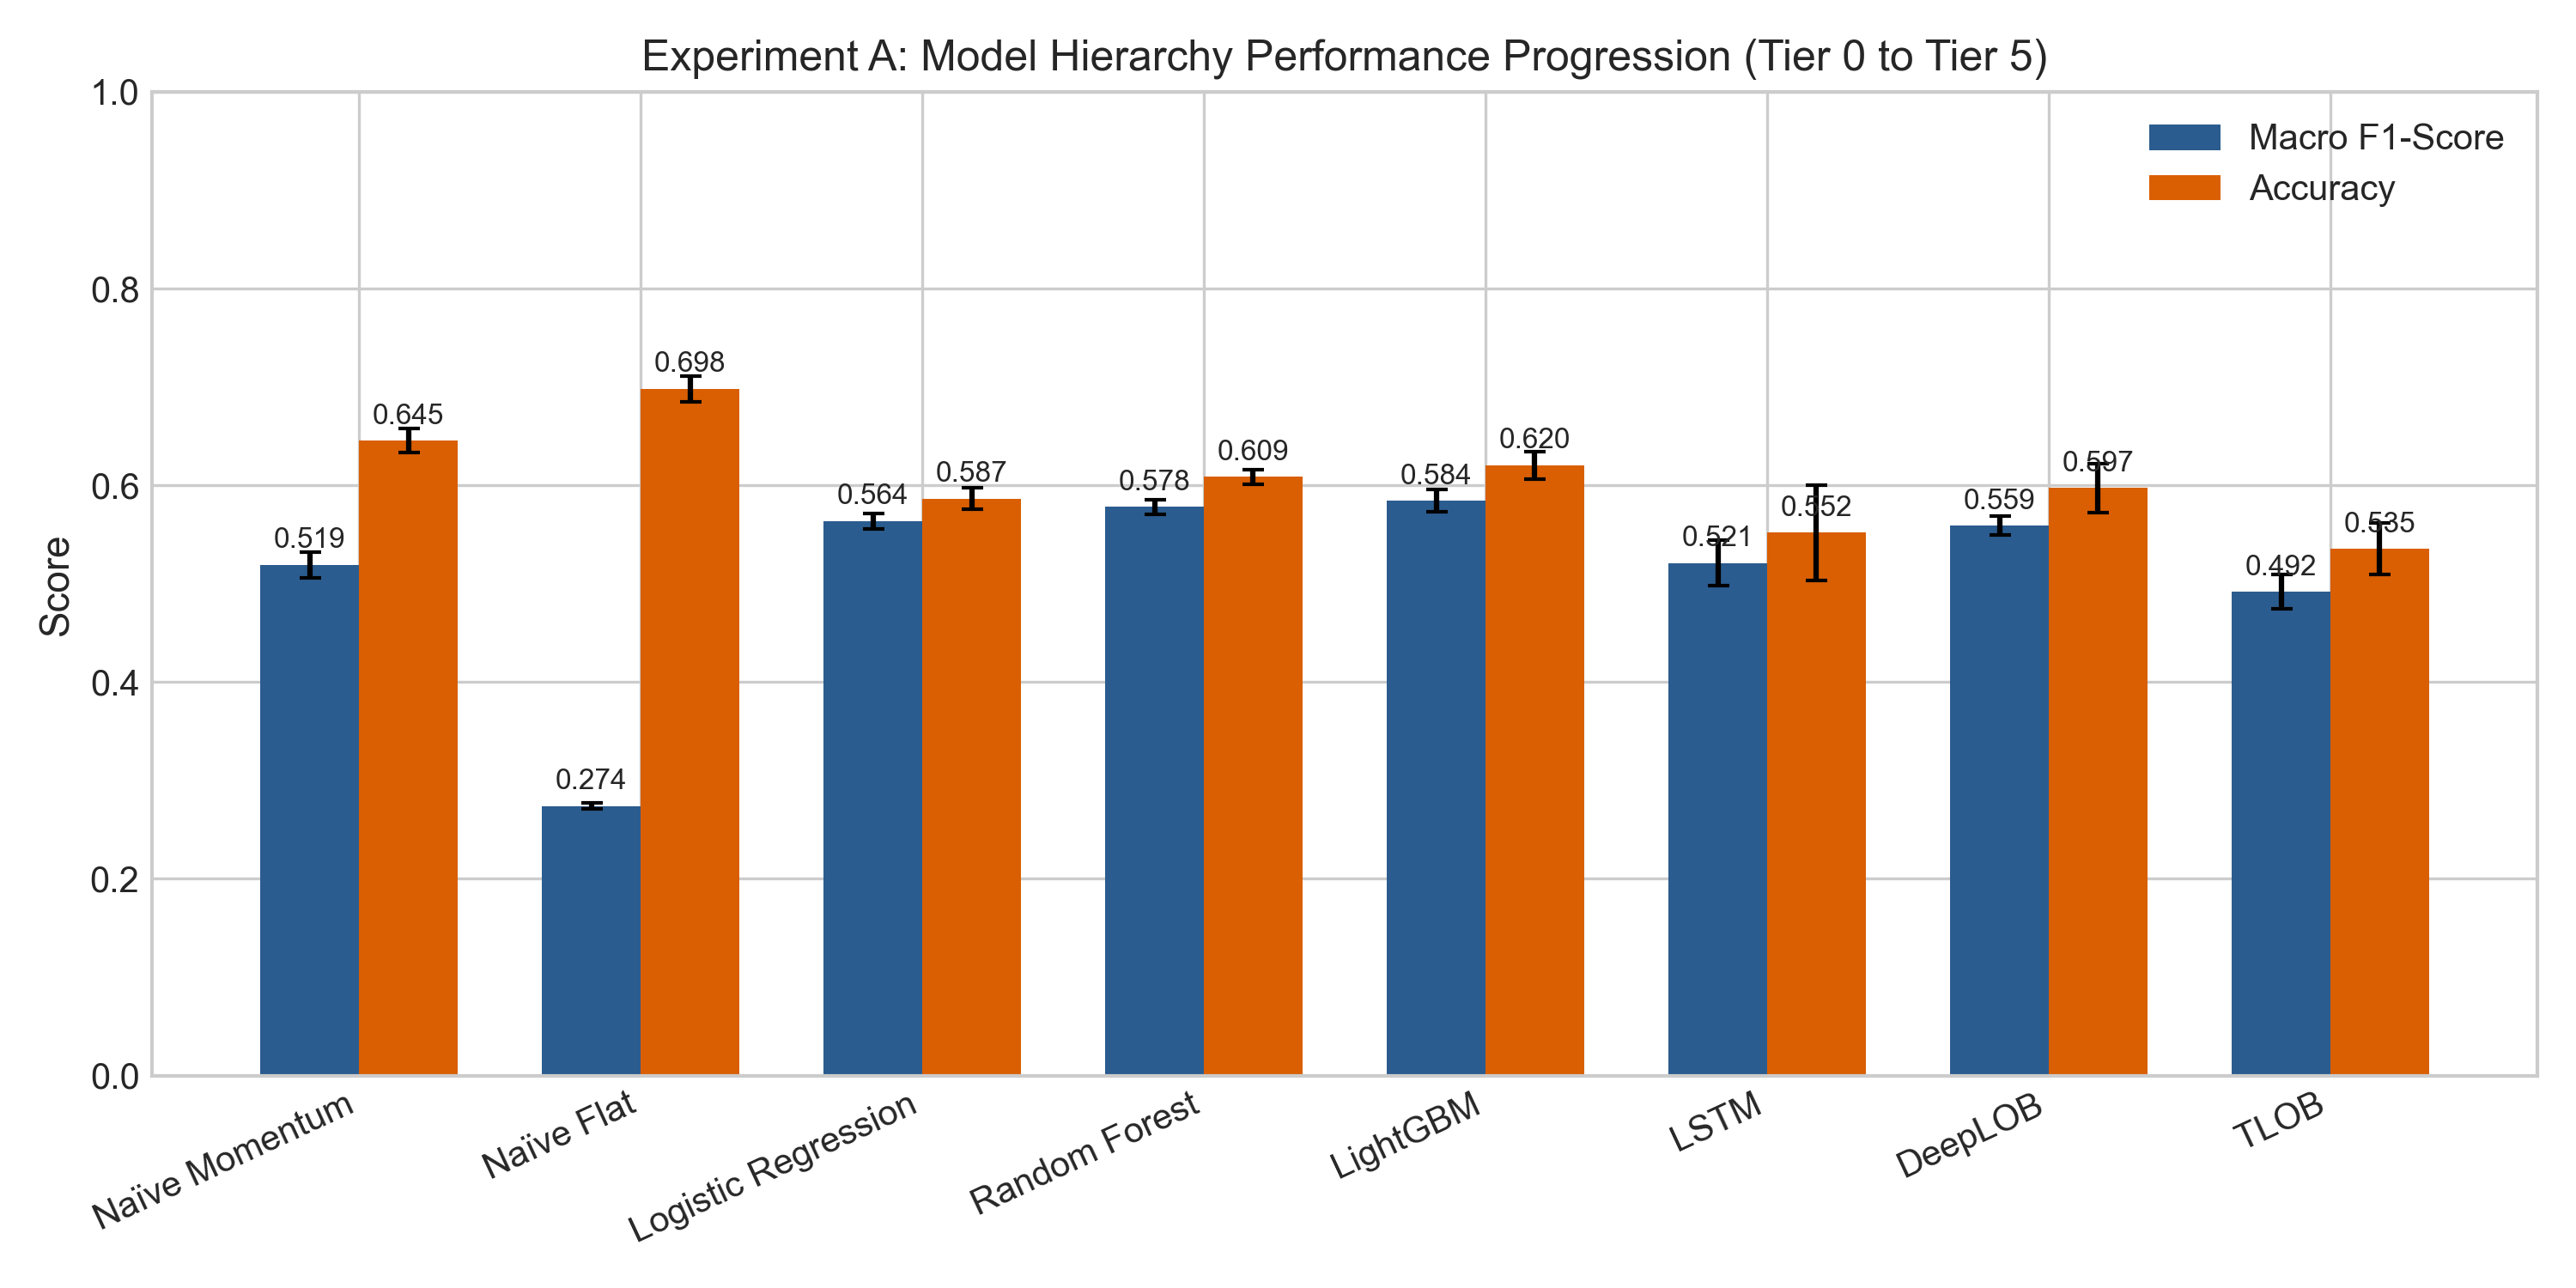

In [9]:
rerun("synthetic")
a = load("experiment_a_results.csv")
show(a[["model", "accuracy", "macro_f1", "macro_f1_std", "cross_entropy"]])
figure("experiment_a_model_comparison.png", 750)

LightGBM is best (macro-F1 0.584 ± 0.012). The sequence models don't beat trees built on hand-crafted microstructure features. LightGBM's lead over Random Forest is within noise.

### 4.2 Experiment B: how fast does the signal decay?

In [10]:
show(load("experiment_b_signal_decay.csv")[["horizon_k", "macro_f1", "macro_f1_std", "momentum_macro_f1", "test_frac_flat"]])

,macro_f1,macro_f1_std,momentum_macro_f1,test_frac_flat
horizon_k,,,,
10,0.521,0.011,0.438,0.883
20,0.581,0.011,0.519,0.698
50,0.534,0.012,0.467,0.387
100,0.453,0.013,0.413,0.221


Skill peaks at k = 20 events and decays beyond it. That matches the 15–60-event bursts the generator plants, which is a sign the pipeline finds what is there and nothing more.

### 4.3 Experiment C: which features carry the signal?

In [11]:
show(load("experiment_c_ablation_results.csv")[["model_tier", "num_features", "macro_f1", "macro_f1_std"]])

,num_features,macro_f1,macro_f1_std
model_tier,,,
Model A: Spread Only,1,0.160,0.102
Model B: L1 Snapshot,4,0.492,0.011
Model C: L1 + Lags,13,0.541,0.006
Model D: L1-L3 + Lags,16,0.570,0.008
Model E: All Features,27,0.581,0.011


The level-1 snapshot carries most of the signal. Short history adds +0.049 and levels 2–3 add +0.029.

### 4.4 Experiment D: execution and latency
The test-set signals of LightGBM and DeepLOB are traded in each session's ~89 s test window, with a 1.5 bp taker fee and 1 ms latency.

In [12]:
d = load("experiment_d_execution_strategies.csv")
show(d[["model", "strategy", "net_pnl", "net_pnl_std", "num_trades", "total_fees", "slippage"]], 1)
lat = load("experiment_d_latency_sharpe.csv")[["latency_ms", "pnl_LightGBM", "pnl_DeepLOB"]]
show(lat, 0)
inf = load("experiment_d_inference_latency.csv").rename(columns={"Unnamed: 0": "statistic"})
show(inf)

,strategy,net_pnl,net_pnl_std,num_trades,total_fees,slippage
model,,,,,,
LightGBM,Academic Mid-Price (Fantasy),1857.6,135.9,658.4,0.0,0.0
LightGBM,Aggressive Taker,457.2,256.9,658.4,982.0,421.8
LightGBM,Passive Maker (VPIN gate),2.4,30.8,4.0,-2.0,0.0
DeepLOB,Academic Mid-Price (Fantasy),1781.8,141.8,796.8,0.0,0.0
DeepLOB,Aggressive Taker,103.6,160.2,796.8,1185.9,500.6
DeepLOB,Passive Maker (VPIN gate),6.6,173.1,10.8,-5.4,0.0


,pnl_LightGBM,pnl_DeepLOB
latency_ms,,
0.00,508.0,155.0
0.05,461.0,110.0
0.50,459.0,107.0
1.00,457.0,104.0
2.00,454.0,100.0
5.00,442.0,89.0
10.00,427.0,71.0
25.00,369.0,14.0
50.00,290.0,-76.0


,lightgbm_python_ms,deeplob_ms
statistic,,
median,0.138,2.365
mean,0.139,2.420
std,0.032,0.130


- **Costs remove most of the profit.** Crossing the spread and paying fees removes about 75% (LightGBM) and 94% (DeepLOB) of the fantasy profit.
- **Both models lose about $4 per millisecond of latency.** LightGBM's ~$350 lead exists at zero latency, so it comes from better signals, not faster inference.
- **Inference speed matters little here.** DeepLOB's extra ~2.3 ms of inference (2.4 ms vs 0.14 ms) costs only about $10.

## 5. Real data: Coinbase BTC-USD, Experiments A–D

The data is split into 4 contiguous segments of about 3 days, each split 70/15/15 in time. Horizons count 1-second snapshots, so k = 20 means 20 seconds ahead. Execution uses Coinbase's top-tier fees (4 bp taker, 0 bp maker) and 0.1 BTC lots.

Showing saved results. (Set RERUN['btc'] = True in section 1 to recompute.)


,accuracy,macro_f1,macro_f1_std
model,,,
Naïve Momentum,0.415,0.413,0.021
Naïve Flat,0.295,0.152,0.010
Logistic Regression,0.463,0.448,0.016
Random Forest,0.474,0.465,0.017
LightGBM,0.476,0.467,0.021
LSTM,0.448,0.397,0.044
DeepLOB,0.429,0.401,0.048
TLOB,0.455,0.449,0.025


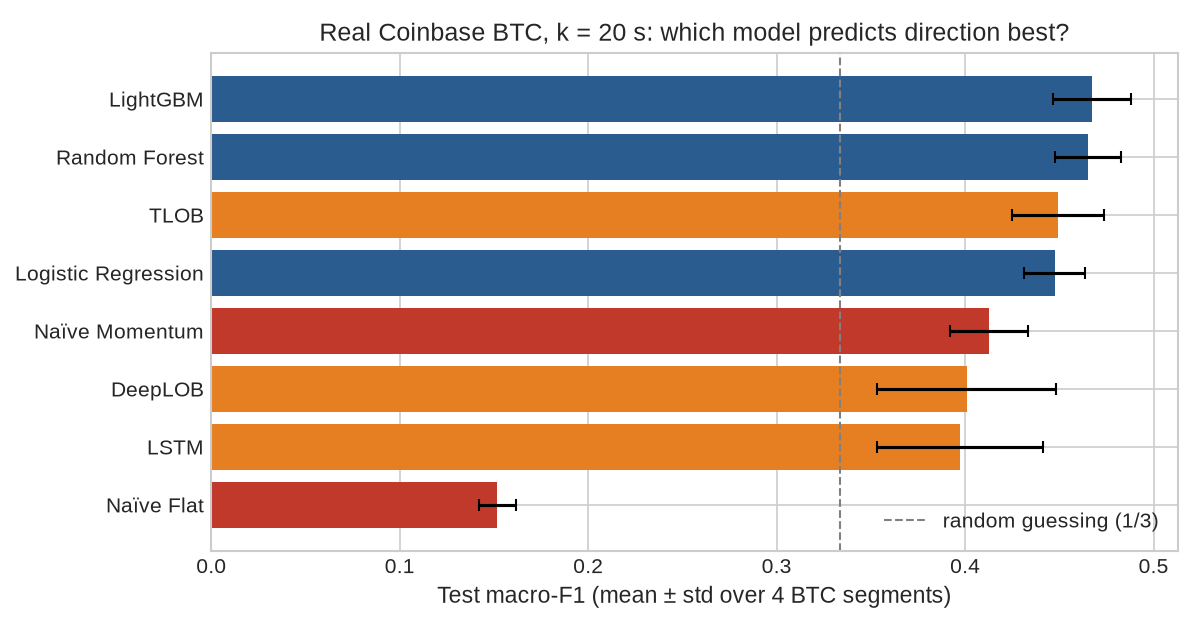

In [13]:
rerun("btc")
b = load("btc/experiment_a_results.csv")
show(b[["model", "accuracy", "macro_f1", "macro_f1_std"]])
figure("figures_real/btc_model_comparison.png", 750)

The signal is real but small: LightGBM reaches 0.467 against 0.413 for momentum and 0.333 for random guessing. DeepLOB (0.401) and the LSTM fall *below* momentum. Section 9 tests whether these gaps are statistically significant.

In [14]:
print("Signal decay (LightGBM vs momentum):")
show(load("btc/experiment_b_signal_decay.csv")[["horizon_k", "macro_f1", "macro_f1_std", "momentum_macro_f1"]])
print("Feature ablation (k = 20 s):")
show(load("btc/experiment_c_ablation_results.csv")[["model_tier", "num_features", "macro_f1", "macro_f1_std"]])

Signal decay (LightGBM vs momentum):


,macro_f1,macro_f1_std,momentum_macro_f1
horizon_k,,,
10,0.540,0.020,0.463
20,0.467,0.021,0.413
50,0.395,0.015,0.367
100,0.350,0.012,0.358


Feature ablation (k = 20 s):


,num_features,macro_f1,macro_f1_std
model_tier,,,
Model A: Spread Only,1,0.237,0.017
Model B: L1 Snapshot,4,0.436,0.016
Model C: L1 + Lags,13,0.460,0.019
Model D: L1-L3 + Lags,16,0.464,0.018
Model E: All Features,27,0.467,0.021


- **The signal decays fast.** Skill is highest at the shortest horizon and gone by 100 s, where LightGBM no longer beats momentum.
- **The top of the book does most of the work.** The level-1 snapshot reaches 0.436, lags add +0.024, and everything deeper adds less than +0.01.

**Execution:**

,strategy,net_pnl,net_pnl_std,num_trades,total_fees
model,,,,,
LightGBM,Academic Mid-Price (Fantasy),8055.0,988.0,15595.0,0.0
LightGBM,Aggressive Taker,-36394.0,7271.0,15595.0,37631.0
LightGBM,Passive Maker (VPIN gate),-478.0,776.0,754.0,0.0
DeepLOB,Academic Mid-Price (Fantasy),5486.0,961.0,13337.0,0.0
DeepLOB,Aggressive Taker,-31071.0,10144.0,13337.0,31809.0
DeepLOB,Passive Maker (VPIN gate),-1411.0,253.0,896.0,0.0


,pnl_LightGBM,pnl_DeepLOB
latency_ms,,
0.0,-34506.0,-29957.0
1000.0,-36394.0,-31071.0
2000.0,-37152.0,-31672.0
5000.0,-38308.0,-32752.0
10000.0,-39961.0,-33961.0
30000.0,-41033.0,-34798.0


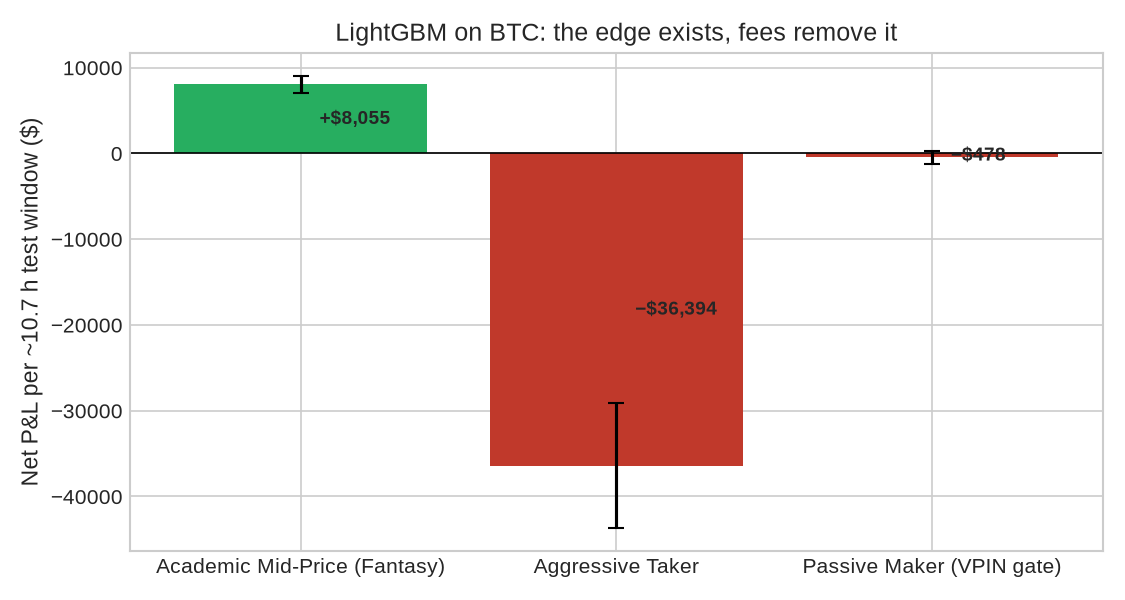

In [15]:
show(load("btc/experiment_d_execution_strategies.csv")[["model", "strategy", "net_pnl", "net_pnl_std", "num_trades", "total_fees"]], 0)
show(load("btc/experiment_d_latency_sharpe.csv")[["latency_ms", "pnl_LightGBM", "pnl_DeepLOB"]], 0)
figure("figures_real/btc_fantasy_vs_real_pnl.png", 650)

- **Fees dominate.** They are about 4.7 times the fantasy profit, and both models lose about $2.3 per taker trade.
- **Latency barely matters here.** Going from 0 to 30 s of latency moves LightGBM only from −$34.5k to −$41.0k, small next to $37.6k of fees.

## 6. From prediction to profit on BTC

### 6.1 Experiment E: can a filtered signal pay?
Each signal is traded as a round trip: enter with a taker order at the next snapshot, exit k seconds later. Only the most confident share of signals is traded ("coverage"). *Cost-aware* labels mark UP only when buying at the ask and selling at the bid later would beat a 4 bp fee per side. "Gross" is bp per round trip after the spread, before fees.

Showing saved results. (Set RERUN['btc_tradability'] = True in section 1 to recompute.)


,horizon_k,coverage,trades,mean_mid_move_bps,mean_gross_bps,hit_rate_gross
label,,,,,,
direction,20,1.000,1666.50,0.924,-0.030,0.477
direction,20,0.200,1263.25,1.525,0.196,0.514
direction,20,0.100,975.25,1.890,0.414,0.535
direction,20,0.050,701.25,2.208,0.545,0.540
direction,20,0.020,404.25,2.175,0.462,0.544
direction,20,0.010,250.00,2.417,0.581,0.569
direction,20,0.005,140.50,2.497,0.585,0.558
cost-aware,20,1.000,1215.50,0.485,-0.358,0.446
cost-aware,20,0.200,1240.75,0.874,-0.104,0.468


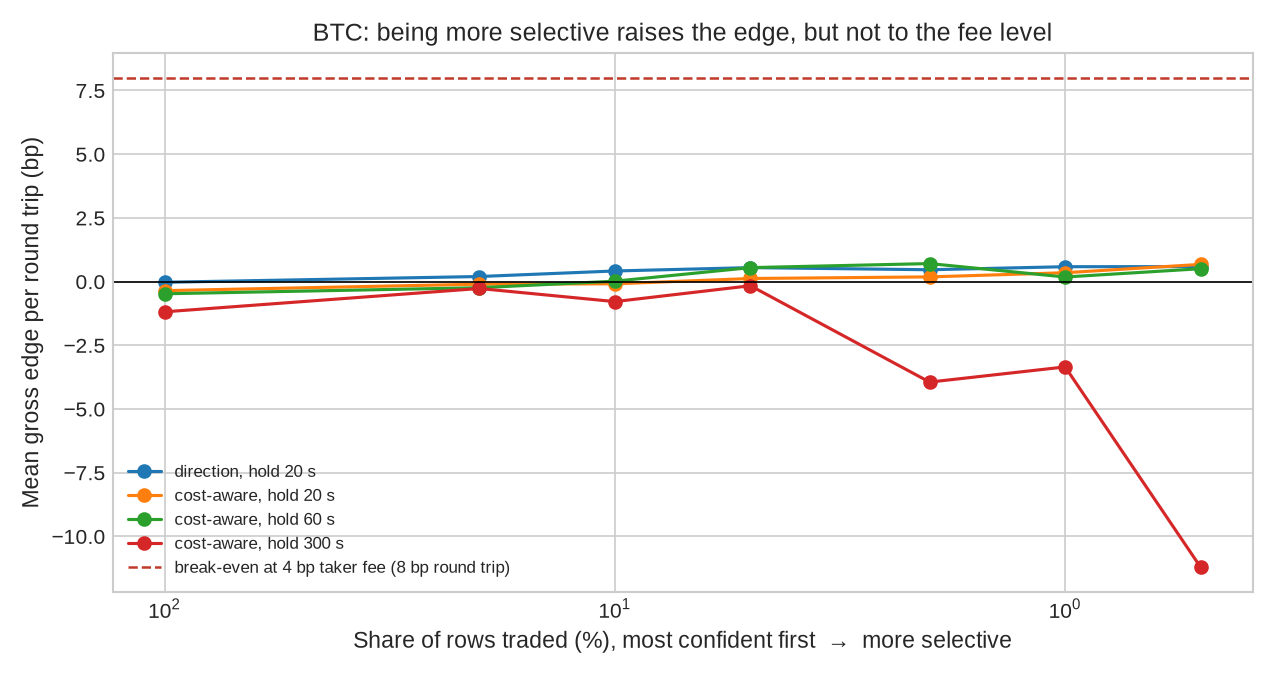

In [16]:
rerun("btc_tradability")
t = load("btc/tradability/tradability_summary.csv")
cols = ["label", "horizon_k", "coverage", "trades_mean", "mean_mid_move_bps_mean", "mean_gross_bps_mean", "hit_rate_gross_mean"]
show(t[cols].rename(columns=lambda c: c.replace("_mean", "")))
figure("figures_real/btc_tradability.png", 700)

Confident signals catch bigger moves, but the best gross edge is 0.70 bp per round trip. At a 4 bp fee per side, breaking even needs 8 bp.

### 6.2 Where exactly does the edge go?
Each round trip is split into three parts:
- the edge at the decision mid;
- the cost of reacting one snapshot (1 s) later;
- the cost of crossing the spread and walking the book.

The break-even hit rate uses the formula from section 2.1.

Showing saved results. (Set RERUN['btc_edge'] = True in section 1 to recompute.)


,horizon_k,coverage,trades,edge_at_decision_mid_bps,delay_cost_bps,crossing_cost_bps,gross_bps,mean_abs_move_bps,hit_rate_at_decision_mid,breakeven_hit_rate_fee0,breakeven_hit_rate_fee1,breakeven_hit_rate_fee4
signal,,,,,,,,,,,,
direction,20,1.00,6359.0,1.010,0.269,0.733,0.009,3.798,0.607,0.632,0.895,1.685
direction,20,0.10,3776.0,1.967,0.646,0.892,0.429,4.218,0.689,0.682,0.919,1.631
direction,20,0.02,1590.0,2.231,0.753,1.011,0.467,4.324,0.718,0.704,0.935,1.629
cost-aware,60,1.00,2322.0,0.415,0.214,0.656,-0.454,6.625,0.521,0.566,0.717,1.169
cost-aware,60,0.10,1658.0,1.074,0.315,0.761,-0.002,6.961,0.569,0.577,0.721,1.152
cost-aware,60,0.02,673.0,1.851,0.373,0.781,0.697,7.337,0.584,0.579,0.715,1.124


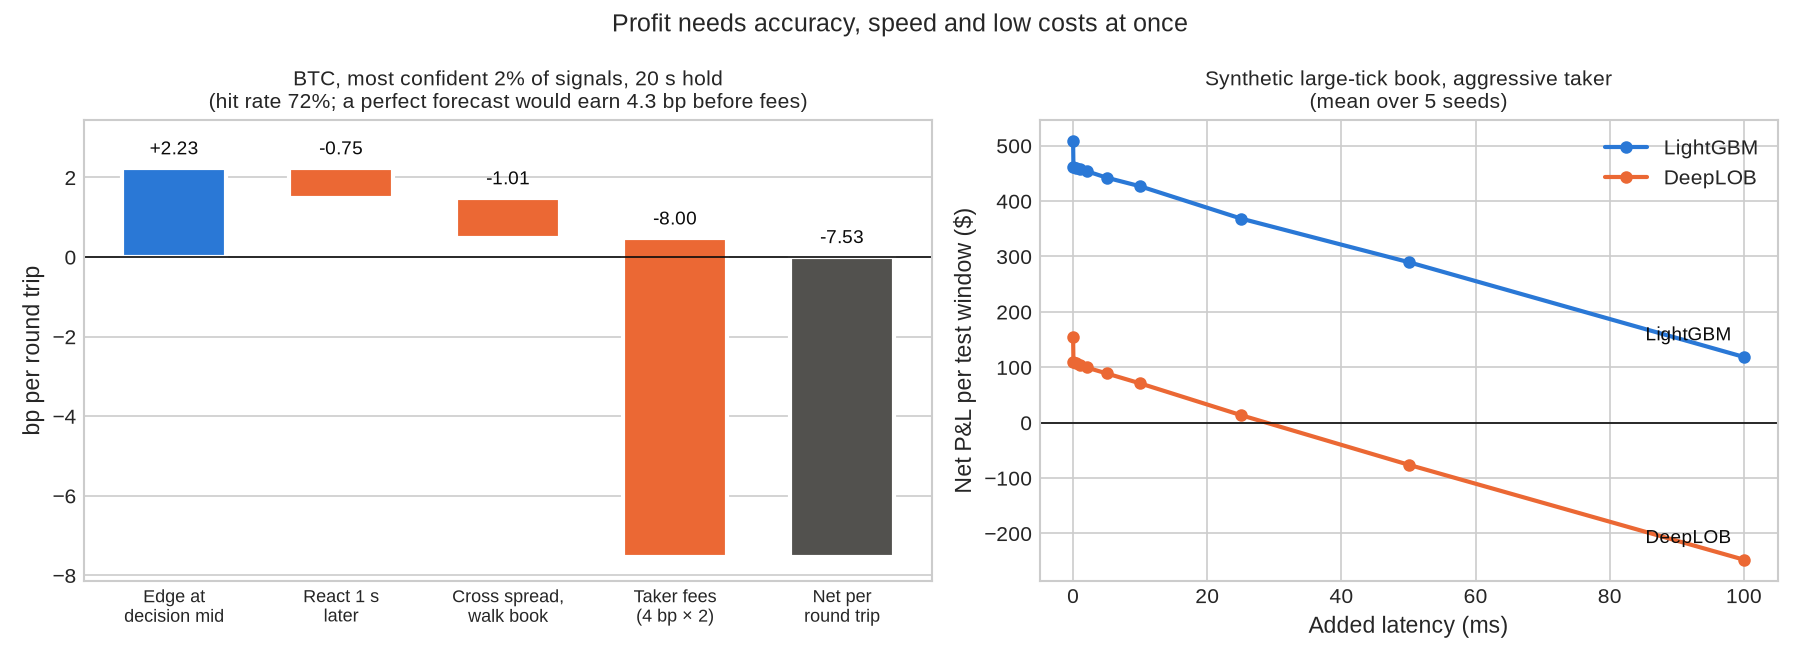

In [17]:
rerun("btc_edge")
e = load("btc/tradability/edge_decomposition.csv")
show(e[["signal", "horizon_k", "coverage", "trades", "edge_at_decision_mid_bps", "delay_cost_bps", "crossing_cost_bps",
        "gross_bps", "mean_abs_move_bps", "hit_rate_at_decision_mid", "breakeven_hit_rate_fee0",
        "breakeven_hit_rate_fee1", "breakeven_hit_rate_fee4"]])
figure("figures_real/accuracy_latency_balance.png", 950)

1. **Better accuracy doubles the edge.** The top 2% of direction signals are right 72% of the time and carry 2.2 bp, against 61% and 1.0 bp for all signals.
2. **Better signals are more latency-sensitive.** The 1 s delay costs the top 2% 0.75 bp, almost three times what it costs the average signal, because they predict the moves that happen soonest.
3. **Without fees, confident signals clear the bar** (72% against the 70% needed).
4. **At the real 4 bp taker fee, no accuracy is enough.** A perfect forecast would earn about 4.3 bp, below the 8 bp round-trip fee, so the break-even hit rate is above 100%.

### 6.3 Experiment G: does the edge survive in any regime?
Trades are split by terciles of VPIN, quoted spread and 60 s realised volatility, with cut-offs from training rows. The 95% CI is a moving-block bootstrap.

In [18]:
rerun("btc_regimes")
g = load("btc/regimes/regime_tradability.csv")
best = g.sort_values("mean_gross_bps", ascending=False).head(6)
show(best[["signal", "coverage", "regime_var", "tercile", "trades", "mean_gross_bps", "gross_ci_low", "gross_ci_high", "segments_gross_positive"]], 2)
skill = load("btc/regimes/regime_skill.csv")
print("Macro-F1 by regime (direction model):")
show(skill[skill.signal == "direction"][["regime_var", "tercile", "mean", "std"]])

Showing saved results. (Set RERUN['btc_regimes'] = True in section 1 to recompute.)


,coverage,regime_var,tercile,trades,mean_gross_bps,gross_ci_low,gross_ci_high,segments_gross_positive
signal,,,,,,,,
cost-aware,0.02,vpin,high,336,1.43,0.24,2.84,3
cost-aware,0.02,vol_60s,low,193,1.32,0.49,2.54,3
direction,0.02,vol_60s,low,413,1.08,0.73,1.47,4
cost-aware,0.02,vol_60s,mid,287,0.95,0.09,1.79,4
direction,0.10,vol_60s,low,1046,0.93,0.64,1.23,4
cost-aware,0.02,spread,mid,171,0.89,-0.14,1.89,3


Macro-F1 by regime (direction model):


,tercile,mean,std
regime_var,,,
vpin,low,0.467,0.026
vpin,mid,0.468,0.031
vpin,high,0.467,0.027
spread,low,0.476,0.035
spread,high,0.426,0.012
vol_60s,low,0.483,0.030
vol_60s,mid,0.452,0.018
vol_60s,high,0.443,0.015
spread,mid,0.465,0.011


- **No regime survives costs.** The best cell earns +1.43 bp gross, and a round trip at even 1 bp per side costs 2 bp.
- **The edge is most consistent in calm markets**, not in "toxic" high-VPIN ones. Macro-F1 is the same in every VPIN tercile.

## 7. More signal: Ethereum's book (Experiment F)
The same LightGBM is trained with and without ETH-USD book features, using the latest ETH snapshot at or before each BTC timestamp.

Showing saved results. (Set RERUN['btc_eth'] = True in section 1 to recompute.)


,btc_only_macro_f1,with_eth_macro_f1,delta_mean,delta_std,segments_improved,segments,eth_gain_share_pct
horizon_k,,,,,,,
10,0.540,0.556,0.016,0.007,4,4,26.530
20,0.467,0.480,0.012,0.005,4,4,31.025
50,0.395,0.402,0.007,0.008,4,4,33.623


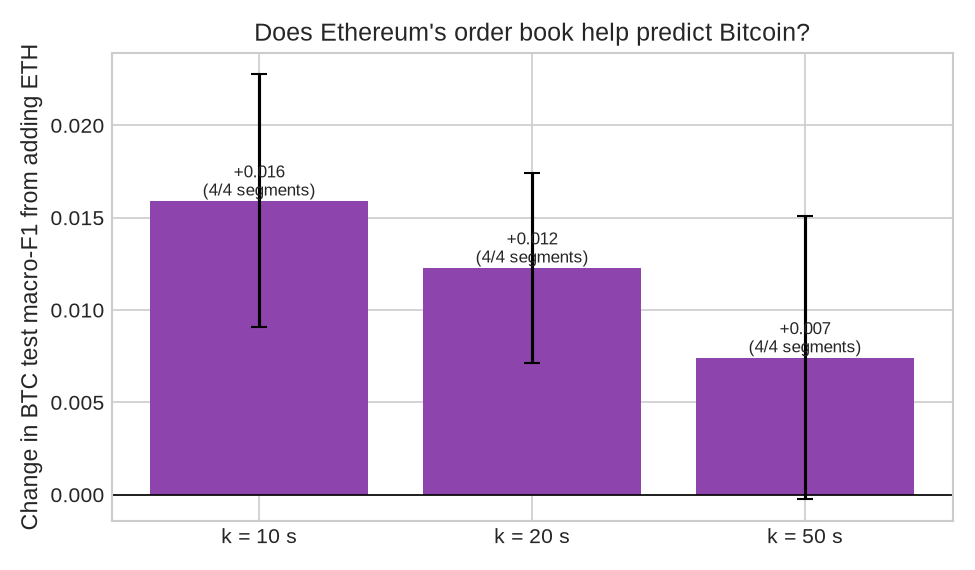

In [19]:
rerun("btc_eth")
show(load("btc/cross_asset/cross_asset_summary.csv"))
figure("figures_real/btc_eth_cross_asset.png", 600)

The gain is small (+0.016 macro-F1 at 10 s) but consistent across all 4 segments, and it fades with horizon. That fits ETH leading BTC by a few seconds.

## 8. Market making (H) and Nasdaq stocks by tick size (I)

### 8.1 Experiment H: market making on BTC
Instead of paying the spread, quote on both sides and earn it. The risk is adverse selection: resting orders fill when the price is about to move against them. LightGBM predicts the value of posting a quote. Each strategy is run under three fill rules, because queue position is not observed.

In [20]:
rerun("btc_market_making")
mm = load("btc/market_making/mm_summary.csv")
show(mm.pivot(index="strategy", columns="fill_rule", values="net_pnl_usd")[["pessimistic", "queue", "optimistic"]].reset_index(), 0)
asel = load("btc/market_making/adverse_selection_summary.csv")
show(asel[["fill_rule", "side", "fill_rate_test", "mean_markout_bp_test", "toxic_auc_test"]])

Showing saved results. (Set RERUN['btc_market_making'] = True in section 1 to recompute.)


fill_rule,pessimistic,queue,optimistic
strategy,,,
always,-4677.0,-4638.0,-4509.0
model,-670.0,-501.0,81.0
rule,-1562.0,-1562.0,-1445.0


,side,fill_rate_test,mean_markout_bp_test,toxic_auc_test
fill_rule,,,,
pessimistic,bid,0.693,-1.867,0.549
pessimistic,ask,0.739,-1.784,0.552
queue,bid,0.702,-1.811,0.545
queue,ask,0.750,-1.717,0.547
optimistic,bid,0.860,-0.753,0.566
optimistic,ask,0.917,-0.596,0.581


- **Naive quoting loses about $10,400 a day.** BTC's spread is 0.0017 bp, so there is nothing to earn, only adverse selection to absorb.
- **The model helps but doesn't break even.** It cuts losses by 86% or more, but breaks even only under optimistic fills.
- **Bad fills are hard to predict.** AUC is only 0.55–0.58 for telling toxic fills from good ones.

### 8.2 Experiment I: large-tick vs small-tick stocks (LOBSTER, one day)
Every Nasdaq order event, resampled to a 100 ms clock. The chart shows the best learned model's macro-F1 minus naive momentum, by horizon.

Showing saved results. (Set RERUN['lobster'] = True in section 1 to recompute.)


horizon,100ms,500ms,1s,5s,10s,30s
ticker,,,,,,
AAPL,-0.020,0.022,0.019,0.003,0.027,0.059
AMZN,-0.066,-0.047,-0.008,-0.042,-0.029,-0.022
GOOG,-0.085,-0.040,-0.027,-0.035,-0.036,0.009
INTC,-0.004,0.019,0.050,0.113,0.098,-0.025
MSFT,-0.005,0.036,0.071,0.042,0.008,0.008


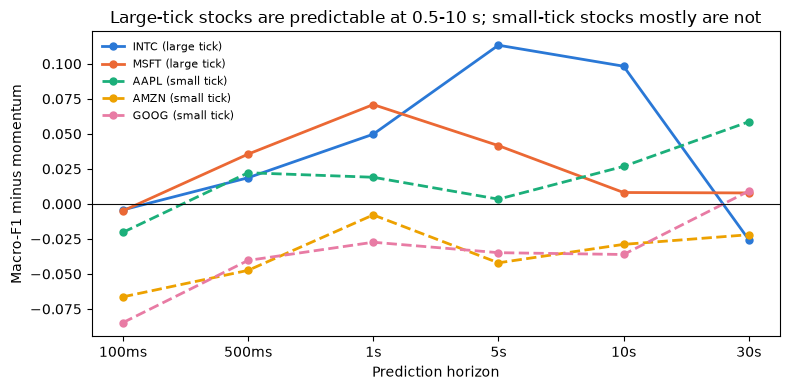

In [21]:
rerun("lobster")
dec = load("lobster/lobster_decay.csv")
dec["lift_over_momentum"] = dec.macro_f1 - dec.momentum_macro_f1
order = ["100ms", "500ms", "1s", "5s", "10s", "30s"]
pivot = dec.pivot(index="ticker", columns="horizon", values="lift_over_momentum")[order]
show(pivot.reset_index())

fig, ax = plt.subplots(figsize=(8, 4))
for ticker, color in zip(["INTC", "MSFT", "AAPL", "AMZN", "GOOG"], [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]):
    style = "-" if ticker in ("INTC", "MSFT") else "--"
    ax.plot(order, pivot.loc[ticker], style, color=color, lw=2, marker="o", ms=5,
            label=f"{ticker} ({'large' if style == '-' else 'small'} tick)")
ax.axhline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("Prediction horizon"); ax.set_ylabel("Macro-F1 minus momentum")
ax.set_title("Large-tick stocks are predictable at 0.5-10 s; small-tick stocks mostly are not")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

- **Large-tick stocks are more predictable,** peaking at 1–5 s (INTC at 5 s: +0.113 macro-F1 over momentum).
- **Nothing is predictable at 100 ms,** because a large-tick mid almost never moves that fast.
- **On small-tick stocks the learned models mostly lose to momentum.**

**Market making on Nasdaq:** mean markout per fill 30 s later, in bp after the rebate, by fill rule.

In [22]:
ls = load("lobster/lobster_adverse_selection.csv")
mk = ls.groupby(["ticker", "fill_rule"]).mean_markout_bp_test.mean().unstack()[["pessimistic", "queue", "optimistic"]]
show(mk.reset_index(), 2)

fill_rule,pessimistic,queue,optimistic
ticker,,,
AAPL,0.14,0.17,0.21
AMZN,0.52,0.55,0.67
GOOG,-0.12,-0.03,0.03
INTC,-2.22,-2.15,1.24
MSFT,-1.78,-1.78,0.70


On large-tick stocks, **queue position decides everything**. A fill at the front of the queue earns +0.7 to +1.2 bp, while one at the back loses about 2 bp. With about 13,000 shares queued at the best price, a new order is almost always at the back. Getting to the front is a speed race, which is why high-frequency firms compete on latency.

## 9. Is the ranking significant, and what do the models use? (Experiment J)

The tabular models and DeepLOB are retrained on each BTC segment (k = 20 s) and their per-row test predictions kept. Two tests:
- **Block bootstrap:** the 95% CI resamples 5-minute blocks, because returns are autocorrelated.
- **McNemar's test:** compares which rows each model gets right.

In [23]:
rerun("attribution")
show(load("btc/attribution/significance_vs_lightgbm.csv")[["other", "macro_f1_diff", "ci_low", "ci_high", "segments_reference_better", "mcnemar_p"]], 4)

Showing saved results. (Set RERUN['attribution'] = True in section 1 to recompute.)


,macro_f1_diff,ci_low,ci_high,segments_reference_better,mcnemar_p
other,,,,,
Naive Momentum,0.0589,0.0501,0.0678,4,0.0000
Logistic Regression,0.0194,0.0154,0.0239,4,0.0000
Random Forest,0.0037,0.0011,0.0065,3,0.0152
DeepLOB,0.0576,0.0486,0.0682,4,0.0000


LightGBM is significantly better than every other model, including DeepLOB (+0.058, on all 4 segments). Its lead over Random Forest is tiny (+0.004).

**What the models rely on.** For LightGBM: exact TreeSHAP values, grouped by feature family. For DeepLOB: gradient × input for the predicted class, on 2,000 test windows per segment.

In [24]:
show(load("btc/attribution/shap_lightgbm_groups.csv"), 1)

att = load("btc/attribution/deeplob_attribution.csv")
per_seg = att.groupby("segment").apply(lambda g: pd.Series({
    "level 1": g[g.level == 1].share_total.sum(),
    "each of levels 2-10 (avg)": g[g.level > 1].share_total.sum() / 9,
    "last 10 of 100 snapshots": g.share_last_10_steps.sum(),
    "order sizes (vs prices)": g[g.kind.str.endswith("size")].share_total.sum()}), include_groups=False)
print("DeepLOB attribution shares, mean over 4 segments:")
display((per_seg.mean() * 100).round(1).rename("share %").to_frame())

,shap_share_pct,gain_share_pct
group,,
Deeper book,39.3,47.1
L1 lags,34.6,25.2
L1 snapshot,14.1,13.6
VPIN,6.6,9.7
Levels 2-3,5.4,4.5
Other,0.0,0.0


DeepLOB attribution shares, mean over 4 segments:


,share %
level 1,18.3
each of levels 2-10 (avg),9.1
last 10 of 100 snapshots,57.4
order sizes (vs prices),84.3


- **Both models rely on the top of the book and very recent history.**
  - LightGBM: level-1 lags carry 35% of its SHAP.
  - DeepLOB: level 1 counts twice as much as any deeper level, and 57% of the weight falls on the last 10 of its 100 snapshots.
- **The sizes-vs-prices split is partly a scaling artefact.** Gradient × input grows with the size of the input, and normalised sizes are much larger numbers than normalised prices.

In [25]:
conf = load("btc/attribution/confusion_matrices.csv")
show(conf[conf.model.isin(["LightGBM", "DeepLOB"])])

,true,pred_FLAT,pred_UP,pred_DOWN
model,,,,
LightGBM,FLAT,0.398,0.282,0.320
LightGBM,UP,0.250,0.499,0.251
LightGBM,DOWN,0.258,0.222,0.520
DeepLOB,FLAT,0.299,0.295,0.406
DeepLOB,UP,0.258,0.417,0.325
DeepLOB,DOWN,0.209,0.254,0.537


FLAT is the hardest class for every model. DeepLOB also leans toward one direction: it calls 41% of FLAT rows DOWN, while LightGBM spreads its errors evenly.

## 10. The micro-price as predictor and target (Experiment K)

The micro-price used here is the imbalance-weighted mid. Its gap from the mid is $I \times \text{spread}/2$, where $I$ is the level-1 queue imbalance. The research spec suggested it as a better *target*. Two questions:
1. Does the mid move toward the micro-price? β is the slope of the future mid change on today's gap, and β = 1 means the gap fully closes.
2. Is the micro-price a better target to train on? Scored by information coefficient (IC), the correlation of the forecast with the realised future mid change.

Showing saved results. (Set RERUN['microprice'] = True in section 1 to recompute.)


,horizon,beta_train,beta_test,gap_abs_mean_bp,mid_move_abs_mean_bp
dataset,,,,,
BTC,10s,0.380,0.404,0.064,2.197
BTC,20s,0.445,0.598,0.064,3.480
BTC,50s,0.690,0.528,0.064,5.885
LOBSTER-small,500ms,0.012,0.026,0.751,0.173
LOBSTER-small,1s,0.020,0.040,0.751,0.305
LOBSTER-small,5s,0.034,0.080,0.751,1.036
LOBSTER-small,10s,0.032,0.087,0.752,1.633
LOBSTER-small,30s,-0.004,0.043,0.754,3.042
LOBSTER-large,500ms,0.120,0.163,0.536,0.105


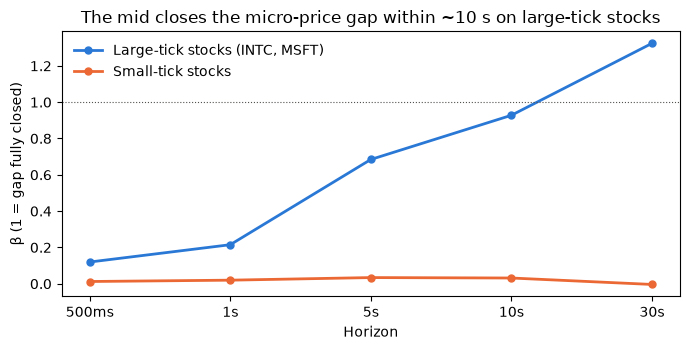

In [26]:
rerun("microprice")
beta = load("microprice/microprice_beta_summary.csv")
show(beta[["dataset", "horizon", "beta_train", "beta_test", "gap_abs_mean_bp", "mid_move_abs_mean_bp"]])

fig, ax = plt.subplots(figsize=(7, 3.6))
for name, color, label in (("LOBSTER-large", BLUE, "Large-tick stocks (INTC, MSFT)"), ("LOBSTER-small", ORANGE, "Small-tick stocks")):
    s = beta[beta.dataset == name]
    ax.plot(s.horizon, s.beta_train, color=color, lw=2, marker="o", ms=5, label=label)
ax.axhline(1, color="#52514e", lw=0.8, ls=":")
ax.set_xlabel("Horizon"); ax.set_ylabel("β (1 = gap fully closed)")
ax.set_title("The mid closes the micro-price gap within ~10 s on large-tick stocks")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

In [27]:
m = load("microprice/microprice_summary.csv")
pick = m[m.model.isin(["Micro-price rule (beta x gap)", "Momentum (past k-step return)", "LightGBM", "LightGBM, shuffled-target control"])]
pick = pick.assign(model=pick.model + " (trained on " + pick.train_target + ")")
ic = pick.pivot_table(index="model", columns=["dataset", "horizon"], values="ic_pearson")
ic = ic[[("LOBSTER-large", "5s"), ("LOBSTER-large", "10s"), ("LOBSTER-small", "1s"), ("BTC", "10s")]]
ic.columns = ["Large-tick 5 s", "Large-tick 10 s", "Small-tick 1 s", "BTC 10 s"]
print("Information coefficient with the future mid change, test period:")
show(ic.reset_index())

Information coefficient with the future mid change, test period:


,Large-tick 5 s,Large-tick 10 s,Small-tick 1 s,BTC 10 s
model,,,,
LightGBM (trained on micro),0.080,0.009,-0.007,0.260
LightGBM (trained on mid),0.209,0.170,0.155,0.263
"LightGBM, shuffled-target control (trained on mid)",-0.003,0.005,-0.003,0.002
Micro-price rule (beta x gap) (trained on mid),0.290,0.278,0.062,0.024
Momentum (past k-step return) (trained on mid),0.037,0.012,0.042,0.074


- **As a predictor, the gap is excellent where the tick is large.** On INTC and MSFT, a one-parameter rule (β × gap) matches or beats LightGBM with about 40 features from 5 s on (IC 0.29 vs 0.21).
- **As a training target, it is worse.** A model trained on micro-price changes is never better than one trained on the mid, and is significantly worse in 21 of 37 cases (block-bootstrap CIs).
- **The shuffled-target control scores about zero,** as it should. An automatic checker (`scripts/check_microprice_results.py`) runs 19 checks on these results.

## 11. FI-2010: comparison with the published DeepLOB

Setup 2: train on days 1–7, test on days 8–10, 3 training seeds. *History* adds lagged changes of the 40 raw book columns, giving the tabular models the past that DeepLOB sees in its window.

Showing saved results. (Set RERUN['fi2010'] = True in section 1 to recompute.)
Test accuracy by horizon k (mean over 3 seeds):


horizon_k,10,20,50,100
model,,,,
Naive Flat,0.707,0.620,0.473,0.344
Logistic Regression,0.708,0.641,0.439,0.400
LightGBM (144 feats),0.532,0.472,0.441,0.428
Logistic Regression + history,0.861,0.783,0.665,0.602
LightGBM (144 feats + history),0.780,0.566,0.644,0.757
DeepLOB (ours),0.831,0.741,0.782,0.775
DeepLOB (published),0.845,0.748,0.805,NaN


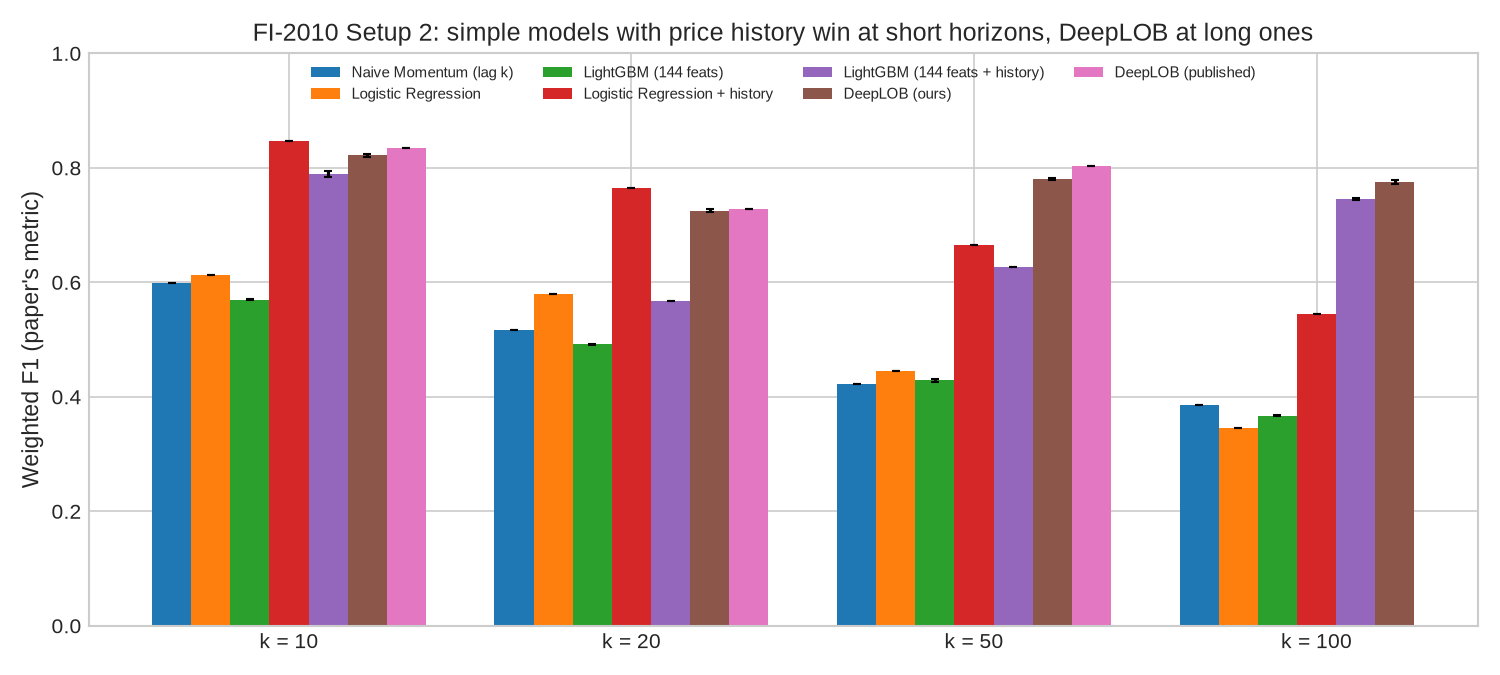

In [28]:
rerun("fi2010")
fi = load("fi2010/fi2010_setup2_summary.csv")
acc = fi.pivot(index="model", columns="horizon_k", values="accuracy_mean").round(3)
order = ["Naive Flat", "Logistic Regression", "LightGBM (144 feats)", "Logistic Regression + history",
         "LightGBM (144 feats + history)", "DeepLOB (ours)", "DeepLOB (published)"]
print("Test accuracy by horizon k (mean over 3 seeds):")
show(acc.loc[order].reset_index())
figure("figures_real/fi2010_comparison.png", 750)

- **The DeepLOB reproduction is sound:** within 0.7–2.3 points of the paper.
- **Short horizons:** logistic regression with history beats DeepLOB (86.1% vs 83.1% at k = 10, 78.3% vs 74.1% at k = 20). DeepLOB's short-horizon advantage comes from seeing history, not from its architecture.
- **Long horizons:** DeepLOB wins clearly at k = 50 and 100.

**Why LightGBM with history fails at k = 20:**

In [29]:
rerun("fi2010_diagnose")
show(load("fi2010/diagnose_lightgbm_history.csv"))

Showing saved results. (Set RERUN['fi2010_diagnose'] = True in section 1 to recompute.)


,setting,rounds,val_accuracy,test_accuracy,test_pred_shares,test_label_shares
horizon_k,,,,,,
10,early stopping (benchmark),356,0.860,0.774,0.62/0.16/0.22,0.71/0.15/0.14
10,fixed rounds,10,0.859,0.877,0.82/0.09/0.09,0.71/0.15/0.14
10,fixed rounds,25,0.860,0.867,0.78/0.10/0.12,0.71/0.15/0.14
10,fixed rounds,50,0.860,0.826,0.70/0.13/0.17,0.71/0.15/0.14
10,fixed rounds,100,0.860,0.790,0.64/0.16/0.20,0.71/0.15/0.14
10,fixed rounds,200,0.860,0.779,0.63/0.17/0.20,0.71/0.15/0.14
10,fixed rounds,300,0.860,0.782,0.63/0.16/0.21,0.71/0.15/0.14
10,fixed rounds,500,0.860,0.779,0.63/0.17/0.21,0.71/0.15/0.14
20,early stopping (benchmark),446,0.876,0.567,0.28/0.41/0.31,0.62/0.20/0.18


It isn't early stopping: test accuracy is 54–57% at every number of rounds. Validation accuracy stays at 86–88% whatever the setting, so it can't detect the problem. The test days are calmer than the training days (FLAT is 62% of test labels against 49% of training labels at k = 20), and LightGBM predicts far too few FLATs on them. It is a distribution shift that validation cannot see.

## 12. Optiver Kaggle data: leakage and the closing auction

### 12.1 Realized Volatility: how much of the winning solution was leakage?
The Kaggle winner recovered the shuffled time order and built nearest-neighbour features from *all* time windows, including future ones. This experiment validates forward in time and compares past-only neighbours with the winner's version (RMSPE, lower is better).

In [30]:
rerun("optiver_rvp")
show(load("optiver_rvp/rvp_summary.csv"), 4)

Showing saved results. (Set RERUN['optiver_rvp'] = True in section 1 to recompute.)


,mean,std
model,,
Naive (current RV),0.3370,0.0174
LightGBM (book/trade features),0.2350,0.0121
"+ NN features, past-only",0.2226,0.0137
"+ NN features, transductive (1st-place style, leaks future)",0.2139,0.0138
"LightGBM, shuffled K-fold CV",0.2142,0.0089


- **About 59% of the neighbour gain survives** without future data (0.0124 of 0.0212 RMSPE).
- **Shuffled K-fold CV makes a plain model look as good as the leaky one.** Validation design changes the conclusion.

### 12.2 Trading at the Close
The winner's split: train on the first 400 days, hold out the last 81. MAE in bp.

In [31]:
rerun("optiver_close")
show(load("optiver_close/close_holdout_results.csv"), 4)

Showing saved results. (Set RERUN['optiver_close'] = True in section 1 to recompute.)


,mae
model,
Zero prediction,5.9936
"LightGBM, trained once",5.8564
"LightGBM, trained once + demean",5.8533
"LightGBM, retrained every 12 days + demean",5.8476


The model improves on predicting zero by about 2.4%, which is the same order as the competition winners' edge. Closing-auction moves are almost unpredictable.

## 13. Latency: the C++ inference benchmarks

The trained BTC LightGBM (327 trees, 20,601 leaves, 27 features) is compiled to plain C++ by a code generator (`scripts/lgbm_to_cpp.py`) and checked against LightGBM on 20,000 test rows. A second benchmark times feature extraction, inference with a random 50-tree ensemble and a simulated order in one loop.

In [32]:
rerun("cpp_trained")
tm = load("cpp_trained_model_benchmark.csv")
show(tm[["num_trees", "total_leaves", "num_features", "cpp_p50_ns", "cpp_p99_ns", "cpp_max_abs_diff_vs_lightgbm", "cpp_argmax_agreement"]], 1)
show(load("cpp_latency_benchmarks.csv"), 1)

Showing saved results. (Set RERUN['cpp_trained'] = True in section 1 to recompute.)


,total_leaves,num_features,cpp_p50_ns,cpp_p99_ns,cpp_max_abs_diff_vs_lightgbm,cpp_argmax_agreement
num_trees,,,,,,
327,20601,27,10500.0,17900.0,0,1.0


,throughput_mps,feat_p50_us,feat_p99_us,inf_p50_us,inf_p99_us,e2e_p50_us,e2e_p90_us,e2e_p99_us,e2e_p999_us
metric,,,,,,,,,
cpp_pipeline,398975,0,0.2,1.8,6.1,1.9,4.6,6.3,15.1


- **The C++ model is exact:** maximum absolute score difference 0, and it agrees with LightGBM on 100% of predicted classes.
- **It takes 10.5 µs at the median and 17.9 µs at P99.** That run shared the CPU with other jobs, so treat it as an upper bound.
- **Inference only:** neither number includes network or market-data handling.

## 14. Discussion: balancing accuracy, latency and cost

| Step | Time |
|:---|:---:|
| BTC data interval (fastest reaction possible in this data) | 1 s |
| LOBSTER clock | 100 ms |
| DeepLOB, one prediction on GPU | 2.4–5.7 ms |
| LightGBM, one prediction from Python | 0.14 ms |
| Trained LightGBM compiled to C++ | 10.5 µs (P50) |
| Micro-price rule | a few arithmetic operations |

**What the evidence says:**

1. **Costs set the bar, and no model clears an impossible bar.** On BTC as a taker, the round-trip cost is larger than the typical move. Even a perfect forecast loses (section 6.2), and lower latency doesn't help either: 1 s → 0 s improves the P&L by only about 5%.
2. **Once the bar can be cleared, accuracy matters most.** On the synthetic book, LightGBM's lead over DeepLOB is worth about $350, while DeepLOB's extra 2.3 ms costs about $10 (section 4.4). Choosing the more accurate model is worth about 35 times more than choosing the faster one.
3. **Accuracy buys latency budget.** DeepLOB's profit is gone by about 29 ms of latency, while LightGBM's is still positive at 100 ms.
4. **But better signals decay faster, so they need lower latency.** On BTC the most confident signals lose almost three times as much to a 1 s delay as average ones (section 6.2). Accuracy and latency are complements, not substitutes.
5. **At short horizons, the best low-latency models are the simple ones that are still accurate.** Examples are LightGBM compiled to C++ and the micro-price rule on large-tick stocks. Deep models win only at longer horizons (FI-2010, k = 50–100), which is where their millisecond inference is affordable.
6. **For passive strategies, speed becomes the edge itself.** On large-tick stocks queue position decides whether a fill earns +1 bp or loses 2 bp (section 8.2).

**The balancing rule:**
1. Check that the typical move over the horizon is comfortably larger than the round-trip cost.
2. Choose the most accurate model whose inference fits well inside the horizon.
3. Spend on latency in proportion to how fast the signal decays.
4. For passive execution, treat latency (queue position) as the main edge and prediction as the filter.

## 15. Limitations and conclusion

**Limitations**
- **Small real samples.** BTC is about 12 days from one exchange and LOBSTER is one day per stock, so treat the LOBSTER results as a case study.
- **Coarse BTC data.** The 1 s snapshots hide sub-second effects, so "1 s delay" is the data's resolution, not a system latency.
- **Fills are bounds.** Queue position is not observed, so passive fills are reported under three rules rather than estimated.
- **No persistent price impact.** Our orders do not deplete later snapshots.
- **The synthetic generator plants its signal,** so its dollar figures show mechanisms, not real-market magnitudes.
- **C++ timings** come from a busy machine and cover inference only.
- **The deep models had limited tuning.**

**Conclusion**

Short-horizon price moves in limit order books are predictable: significantly, but slightly. Tree models on hand-crafted microstructure features match or beat deep sequence models at the horizons that matter for trading, and a one-parameter micro-price rule is as good as LightGBM on large-tick stocks a few seconds ahead.

Turning prediction into profit is a three-way balance:
- **Costs** decide whether a profit is possible at all.
- **Accuracy** decides whether you clear the bar.
- **Latency** matters in proportion to how fast the signal decays, and better signals decay faster.

**Reproducibility**
- Tests: `python -m pytest tests` (40 tests).
- Full reruns: `notebooks/colab_run_all.ipynb`.
- Per-experiment commands: the README.